In [ ]:
import os
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

1. LOAD DATASET & GENERATOR

In [ ]:
print("Mulai mengunduh dataset dari Kaggle...")
dataset_path = kagglehub.dataset_download("agungmrf/indonesian-sign-language-bisindo")
print(f"Dataset berhasil diunduh ke: {dataset_path}")

# Tentukan path utama tempat folder 'images' dan 'labels' berada
base_dir = os.path.join(dataset_path, "bisindo")
# Path ke folder gambar
train_dir = os.path.join(base_dir, 'images', 'train')
val_dir = os.path.join(base_dir, 'images', 'val')

IMAGE_SIZE = (64, 64)
BATCH_SIZE = 32

# Inisialisasi ImageDataGenerator dengan normalisasi dan augmentasi ringan
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=False,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255) # Hanya normalisasi untuk validasi

# Buat generator untuk data pelatihan
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Buat generator untuk data validasi
validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMAGE_SIZE,
    color_mode='grayscale',
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

num_classes = train_generator.num_classes
label_names = list(train_generator.class_indices.keys())
print(f"Kelas terdeteksi ({num_classes}): {label_names}")

Mulai mengunduh dataset dari Kaggle...
Using Colab cache for faster access to the 'indonesian-sign-language-bisindo' dataset.
Dataset berhasil diunduh ke: /kaggle/input/indonesian-sign-language-bisindo
Found 9169 images belonging to 26 classes.
Found 2301 images belonging to 26 classes.
Kelas terdeteksi (26): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


2. CNN MODEL

In [ ]:
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(64,64,1)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         6,682 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,279,258 (4.88 MB)

 Trainable params: 1,279,258 (4.88 MB)

 Non-trainable params: 0 (0.00 B)

3. CALLBACKS & TRAIN

In [ ]:
# 1. Early Stopping: Menghentikan pelatihan jika loss validasi tidak membaik
#    Patience 10 memberikan cukup waktu setelah Learning Rate diturunkan
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# 2. Reduce LR On Plateau: Implementasi "tambah 5 epoch lagi"
#    Jika akurasi validasi terhenti selama 5 epoch, Learning Rate diturunkan
#    sehingga model dapat terus belajar lebih halus.
reduce_lr = ReduceLROnPlateau(
    monitor='val_accuracy',
    factor=0.5, # Turunkan Learning Rate menjadi setengahnya
    patience=5,
    min_lr=0.00001,
    verbose=1
)

# 3. Model Checkpoint: Menyimpan model terbaik
model_checkpoint = ModelCheckpoint(
    'bisindo_best_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

print("\nMulai pelatihan model...")
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=30, # Jumlah epoch tinggi, EarlyStopping akan menghentikannya
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr, model_checkpoint] # Tambahkan reduce_lr
)


Mulai pelatihan model...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.1223 - loss: 3.0185
Epoch 1: val_accuracy improved from -inf to 0.71083, saving model to bisindo_best_model.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 83s 269ms/step - accuracy: 0.1228 - loss: 3.0170 - val_accuracy: 0.7108 - val_loss: 1.1114 - learning_rate: 0.0010
Epoch 2/30
  1/286 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5938 - loss: 1.6530

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy did not improve from 0.71083
286/286 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.5938 - loss: 1.6530 - val_accuracy: 0.6976 - val_loss: 1.1688 - learning_rate: 0.0010
Epoch 3/30
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.5892 - loss: 1.4693
Epoch 3: val_accuracy improved from 0.71083 to 0.76673, saving model to bisindo_best_model.h5


... (11 outputs left out)

286/286 ━━━━━━━━━━━━━━━━━━━━ 51s 178ms/step - accuracy: 0.8406 - loss: 0.5296 - val_accuracy: 0.8979 - val_loss: 0.3562 - learning_rate: 0.0010
Epoch 22/30
  1/286 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8750 - loss: 0.4723
Epoch 22: val_accuracy improved from 0.89789 to 0.90053, saving model to bisindo_best_model.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.8750 - loss: 0.4723 - val_accuracy: 0.9005 - val_loss: 0.3513 - learning_rate: 0.0010
Epoch 23/30
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.8453 - loss: 0.4880
Epoch 23: val_accuracy did not improve from 0.90053
286/286 ━━━━━━━━━━━━━━━━━━━━ 49s 171ms/step - accuracy: 0.8453 - loss: 0.4880 - val_accuracy: 0.8988 - val_loss: 0.3305 - learning_rate: 0.0010
Epoch 24/30
  1/286 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8750 - loss: 0.3912
Epoch 24: val_accuracy did not improve from 0.90053
286/286 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.8750 - loss: 0.3912 - val_accuracy: 0.8974 - val_loss: 0.3310 - learning_rate: 0.0010
Epoch 25/30
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.8494 - loss: 0.4922
Epoch 25: val_accuracy did not improve from 0.90053
286/286 ━━━━━━━━━━━━━━━━━━━━ 50s 176ms/step - accuracy: 0.8494 - loss: 0.4922 - val_accuracy: 0.8974 - val_loss: 0.3300 - learning_rate: 0.0010
Epoch 

286/286 ━━━━━━━━━━━━━━━━━━━━ 50s 173ms/step - accuracy: 0.8648 - loss: 0.4357 - val_accuracy: 0.9018 - val_loss: 0.3217 - learning_rate: 0.0010
Epoch 28/30
  1/286 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7188 - loss: 0.8397
Epoch 28: val_accuracy improved from 0.90185 to 0.90449, saving model to bisindo_best_model.h5


286/286 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.7188 - loss: 0.8397 - val_accuracy: 0.9045 - val_loss: 0.3233 - learning_rate: 0.0010
Epoch 29/30
286/286 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.8701 - loss: 0.4049
Epoch 29: val_accuracy did not improve from 0.90449
286/286 ━━━━━━━━━━━━━━━━━━━━ 50s 174ms/step - accuracy: 0.8701 - loss: 0.4050 - val_accuracy: 0.9045 - val_loss: 0.3049 - learning_rate: 0.0010
Epoch 30/30
  1/286 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8438 - loss: 0.5593
Epoch 30: val_accuracy did not improve from 0.90449
286/286 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - accuracy: 0.8438 - loss: 0.5593 - val_accuracy: 0.9040 - val_loss: 0.3023 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 30.


4. EVALUATE & SAVE

In [ ]:
print("\nEvaluasi Model pada Data Validasi...")
loss, acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {acc*100:.2f}%")

model.save("bisindo_final_model.h5")
print("Model final disimpan sebagai: bisindo_final_model.h5")


Evaluasi Model pada Data Validasi...
72/72 ━━━━━━━━━━━━━━━━━━━━ 10s 135ms/step - accuracy: 0.9082 - loss: 0.2985


Validation Accuracy: 90.44%
Model final disimpan sebagai: bisindo_final_model.h5


5. VISUALISASI HASIL

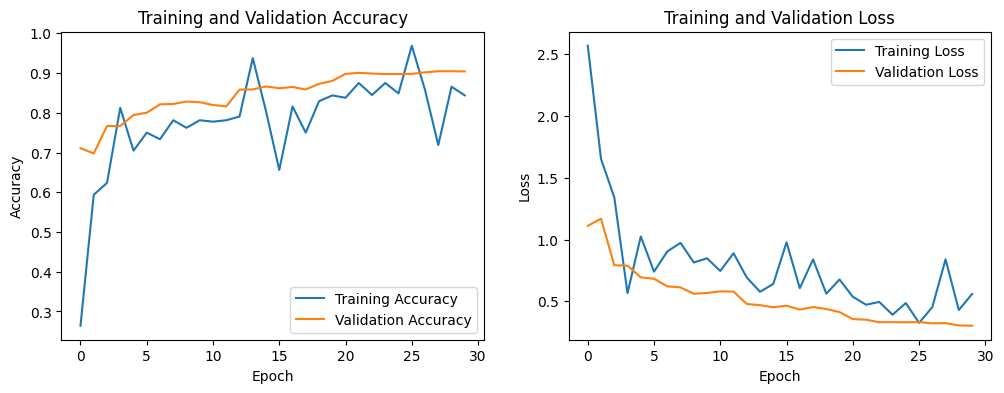

In [ ]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()